# EDA pipeline for the 3D-IRCADb-01 dataset

# Environment Setup & Data Ingestion

In [1]:
!pip install -q pydicom SimpleITK nibabel scipy matplotlib seaborn pandas tqdm tabulate

In [2]:
import os
import re
import shutil
import urllib.request
import zipfile
from pathlib import Path
from tqdm import tqdm

# Path Definitions
BASE_DATA_DIR = Path("./data")
MASTER_ZIP_PATH = BASE_DATA_DIR / "3Dircadb1.zip"
TEMP_RAW_DIR = BASE_DATA_DIR / "temp_raw"
DATASET_ROOT = BASE_DATA_DIR / "3Dircadb1"
DOWNLOAD_URL = "https://cloud.ircad.fr/index.php/s/JN3z7EynBiwYyjy/download"

BASE_DATA_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Download Helper
class TqdmUpTo(tqdm):

    def update_to(self, b=1, bsize=1, tsize=None):
        if tsize is not None:
            self.total = tsize
        self.update(b * bsize - self.n)


if not MASTER_ZIP_PATH.exists():
    print("Step 1/4: Downloading 3D-IRCADb-01 archive...")
    with TqdmUpTo(
        unit="B",
        unit_scale=True,
        unit_divisor=1024,
        miniters=1,
        desc="IRCAD Download",
    ) as t:
        urllib.request.urlretrieve(
            DOWNLOAD_URL, filename=str(MASTER_ZIP_PATH), reporthook=t.update_to
        )
    print("Download complete.")
else:
    print(
        f"Archive already present at {MASTER_ZIP_PATH}. Skipping download."
    )

Step 1/4: Downloading 3D-IRCADb-01 archive...


IRCAD Download: 782MB [00:47, 17.4MB/s]

Download complete.


In [4]:
# Extract Archive
print("\nStep 2/4: Unpacking archive into temporary workspace...")
if TEMP_RAW_DIR.exists():
    shutil.rmtree(TEMP_RAW_DIR)
TEMP_RAW_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(MASTER_ZIP_PATH, "r") as master_ref:
    master_ref.extractall(TEMP_RAW_DIR)

# Locate and Group Component Zips by Patient
all_nested_zips = sorted(list(TEMP_RAW_DIR.rglob("*.zip")))
print(
    f"Found {len(all_nested_zips)} component zip archives (expected: 80 = 20 patients × 4 folders)."
)

# Map archives to patient IDs (3Dircadb1.1 to 3Dircadb1.20)
patient_zip_map = {}
for z_path in all_nested_zips:
    match = re.search(r"3Dircadb1\.(\d+)", str(z_path), re.IGNORECASE)
    if match:
        p_id = f"3Dircadb1.{match.group(1)}"
        patient_zip_map.setdefault(p_id, []).append(z_path)

if DATASET_ROOT.exists():
    shutil.rmtree(DATASET_ROOT)
DATASET_ROOT.mkdir(parents=True, exist_ok=True)


Step 2/4: Unpacking archive into temporary workspace...
Found 80 component zip archives (expected: 80 = 20 patients × 4 folders).


In [5]:
# Extract Patient Sub-Archives
print("\nStep 3/4: Assembling 20 clean patient directories...")
for p_id, zips in tqdm(patient_zip_map.items(), desc="Extracting Patients"):
    p_dest = DATASET_ROOT / p_id
    p_dest.mkdir(parents=True, exist_ok=True)

    for sub_zip in zips:
        with zipfile.ZipFile(sub_zip, "r") as ref:
            # Inspect internal layout: if root folder is already present in zip, extract to p_dest;
            # otherwise extract into a folder named after the sub-zip
            first_name = ref.namelist()[0]
            first_component = first_name.split("/")[0]

            if first_component in [
                "PATIENT_DICOM",
                "MASKS_DICOM",
                "LABELLED_DICOM",
                "MESHES_VTK",
            ]:
                ref.extractall(p_dest)
            else:
                target_folder = p_dest / sub_zip.stem
                target_folder.mkdir(parents=True, exist_ok=True)
                ref.extractall(target_folder)

# Flatten any redundant nested folders (e.g., PATIENT_DICOM/PATIENT_DICOM/ -> PATIENT_DICOM/)
for p_folder in DATASET_ROOT.iterdir():
    if not p_folder.is_dir():
        continue
    for sub in ["PATIENT_DICOM", "LABELLED_DICOM", "MASKS_DICOM", "MESHES_VTK"]:
        nested = p_folder / sub / sub
        if nested.exists() and nested.is_dir():
            for item in nested.iterdir():
                dest = p_folder / sub / item.name
                if not dest.exists():
                    shutil.move(str(item), str(dest))
            shutil.rmtree(nested)


Step 3/4: Assembling 20 clean patient directories...


Extracting Patients: 100%|██████████| 20/20 [01:11<00:00,  3.56s/it]


In [6]:
# Cleanup Temporary Files
print("\nStep 4/4: Cleaning temporary files...")
shutil.rmtree(TEMP_RAW_DIR)
print("Temporary raw files purged.")


Step 4/4: Cleaning temporary files...
Temporary raw files purged.


In [7]:
# Validation Report
patients_found = sorted(
    [d for d in DATASET_ROOT.iterdir() if d.is_dir()],
    key=lambda d: int(d.name.split(".")[-1]),
)

print("\n" + "=" * 70)
print(f"STATUS REPORT: {len(patients_found)} Patients Successfully Assembled")
print("=" * 70)
for p in patients_found[:3]:  # Print first 3 as verification sample
    n_ct = (
        len(list((p / "PATIENT_DICOM").glob("*")))
        if (p / "PATIENT_DICOM").exists()
        else 0
    )
    masks = (
        [d.name for d in (p / "MASKS_DICOM").iterdir() if d.is_dir()]
        if (p / "MASKS_DICOM").exists()
        else []
    )
    print(f"  [{p.name}]")
    print(f"    • CT Slices in PATIENT_DICOM: {n_ct}")
    print(f"    • Mask Structures Found:     {', '.join(masks[:5])}...")
print("=" * 70)
print(f"Global dataset root variable set to: DATASET_ROOT = {DATASET_ROOT}")


STATUS REPORT: 20 Patients Successfully Assembled
  [3Dircadb1.1]
    • CT Slices in PATIENT_DICOM: 129
    • Mask Structures Found:     livertumor06, rightlung, livertumor05, leftkidney, livertumor03...
  [3Dircadb1.2]
    • CT Slices in PATIENT_DICOM: 172
    • Mask Structures Found:     livertumor, gallbladder, skin, venacava, bone...
  [3Dircadb1.3]
    • CT Slices in PATIENT_DICOM: 200
    • Mask Structures Found:     rightlung, livertumor, spleen, leftlung, skin...
Global dataset root variable set to: DATASET_ROOT = data/3Dircadb1


____________

# Dataset Parser

In [8]:
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple
import numpy as np
import pandas as pd
import pydicom
from scipy import ndimage

In [9]:
@dataclass
class PatientVolume:
    patient_id: str
    image: np.ndarray  # Shape: [D, H, W] in Hounsfield Units
    liver_mask: np.ndarray  # Shape: [D, H, W] (bool)
    tumor_mask: np.ndarray  # Shape: [D, H, W] (bool)
    spacing: Tuple[float, float, float]  # (dz, dy, dx) in mm
    num_slices: int
    has_tumor: bool
    num_tumors: int

In [10]:
class IRCADbParser:

    def __init__(self, root_dir: Path):
        self.root_dir = Path(root_dir)

        # Natural numerical sort: 3Dircadb1.1 through 3Dircadb1.20 in strict numerical order
        self.patient_dirs = sorted(
            [
                d
                for d in self.root_dir.iterdir()
                if d.is_dir() and (d / "PATIENT_DICOM").exists()
            ],
            key=lambda d: (
                int(d.name.split(".")[-1]) if "." in d.name else d.name
            ),
        )

        if len(self.patient_dirs) == 0:
            raise FileNotFoundError(
                f"No patient folders with PATIENT_DICOM found in {self.root_dir}"
            )

        print(
            f"Parser initialized. Found {len(self.patient_dirs)} patient volumes (1 to 20)."
        )

    def _load_dicom_series(
        self, series_dir: Path
    ) -> Tuple[np.ndarray, List[Tuple[pydicom.FileDataset, str]]]:
        """Loads and sorts CT slices along the z-axis, applying rescale slope and intercept."""
        slice_files = [f for f in series_dir.iterdir() if f.is_file()]

        # Read datasets paired with their original filenames
        ds_pairs = []
        for f in slice_files:
            ds = pydicom.dcmread(str(f), stop_before_pixels=False)
            ds_pairs.append((ds, f.name))

        # Sort spatially along physical z-coordinate
        if hasattr(ds_pairs[0][0], "ImagePositionPatient"):
            ds_pairs.sort(key=lambda item: float(item[0].ImagePositionPatient[2]))
        elif hasattr(ds_pairs[0][0], "InstanceNumber"):
            ds_pairs.sort(key=lambda item: float(item[0].InstanceNumber))
        else:
            ds_pairs.sort(
                key=lambda item: (
                    int(item[1].split("_")[-1])
                    if "_" in item[1]
                    else item[1]
                )
            )

        # Convert to calibrated Hounsfield Units
        slices = []
        for ds, _ in ds_pairs:
            arr = ds.pixel_array.astype(np.float32)
            slope = float(getattr(ds, "RescaleSlope", 1.0))
            intercept = float(getattr(ds, "RescaleIntercept", 0.0))
            hu = arr * slope + intercept
            slices.append(hu)

        volume = np.stack(slices, axis=0)
        return volume, ds_pairs

    def _load_mask_series(
        self,
        mask_dir: Path,
        ref_ds_pairs: List[Tuple[pydicom.FileDataset, str]],
    ) -> np.ndarray:
        """Loads mask slices matching the corresponding CT slice names."""
        ref_shape = (
            len(ref_ds_pairs),
            ref_ds_pairs[0][0].Rows,
            ref_ds_pairs[0][0].Columns,
        )
        if not mask_dir.exists():
            return np.zeros(ref_shape, dtype=bool)

        mask_slices = []
        for _, fname in ref_ds_pairs:
            slice_path = mask_dir / fname
            if slice_path.exists():
                mask_ds = pydicom.dcmread(str(slice_path))
                mask_slices.append(mask_ds.pixel_array > 0)
            else:
                mask_slices.append(
                    np.zeros(
                        (ref_ds_pairs[0][0].Rows, ref_ds_pairs[0][0].Columns),
                        dtype=bool,
                    )
                )

        return np.stack(mask_slices, axis=0)

    def load_patient(self, patient_idx: int) -> PatientVolume:
        patient_path = self.patient_dirs[patient_idx]
        patient_id = patient_path.name

        # 1. Load CT Scan
        ct_dir = patient_path / "PATIENT_DICOM"
        ct_volume, ref_ds_pairs = self._load_dicom_series(ct_dir)

        # 2. Extract Spacing (dz, dy, dx) in mm
        dx = float(ref_ds_pairs[0][0].PixelSpacing[0])
        dy = float(ref_ds_pairs[0][0].PixelSpacing[1])
        if len(ref_ds_pairs) > 1 and hasattr(
            ref_ds_pairs[0][0], "ImagePositionPatient"
        ):
            dz = abs(
                float(ref_ds_pairs[1][0].ImagePositionPatient[2])
                - float(ref_ds_pairs[0][0].ImagePositionPatient[2])
            )
        else:
            dz = float(getattr(ref_ds_pairs[0][0], "SliceThickness", 1.0))
        spacing = (dz, dy, dx)

        # 3. Load Liver Mask
        masks_parent = patient_path / "MASKS_DICOM"
        liver_mask = self._load_mask_series(
            masks_parent / "liver", ref_ds_pairs
        )

        # 4. Load & Aggregate All Tumor Folders (e.g., 'livertumor', 'livertumor01', 'livertumor02', etc.)
        tumor_mask = np.zeros_like(liver_mask, dtype=bool)
        tumor_dirs = sorted(list(masks_parent.glob("livertumor*")))
        for t_dir in tumor_dirs:
            t_sub = self._load_mask_series(t_dir, ref_ds_pairs)
            tumor_mask = np.logical_or(tumor_mask, t_sub)

        # 5. Connected Component Analysis for Distinct Lesion Instances
        labeled_tumors, num_tumors = ndimage.label(tumor_mask)

        return PatientVolume(
            patient_id=patient_id,
            image=ct_volume,
            liver_mask=liver_mask,
            tumor_mask=tumor_mask,
            spacing=spacing,
            num_slices=ct_volume.shape[0],
            has_tumor=num_tumors > 0,
            num_tumors=num_tumors,
        )

____________

# Patient Level and Lesion Level Statistics

In [11]:
from tabulate import tabulate

parser = IRCADbParser(DATASET_ROOT)

patient_stats = []
lesion_records = []

total_voxels_bg = 0
total_voxels_liver = 0
total_voxels_tumor = 0
total_slices_all = 0
tumor_bearing_slices_all = 0

print("\nExtracting volumetric and lesion-level statistics...")

for idx in range(len(parser.patient_dirs)):
    pat = parser.load_patient(idx)
    dz, dy, dx = pat.spacing
    voxel_volume_mm3 = dz * dy * dx
    voxel_volume_cm3 = voxel_volume_mm3 / 1000.0

    # Voxel Counts (Mutually exclusive: healthy liver excludes tumor)
    n_tumor_vox = np.sum(pat.tumor_mask)
    n_liver_vox = (
        np.sum(pat.liver_mask & (~pat.tumor_mask))
    )  # Pure healthy liver
    n_total_vox = pat.image.size
    n_bg_vox = n_total_vox - (n_liver_vox + n_tumor_vox)

    total_voxels_bg += n_bg_vox
    total_voxels_liver += n_liver_vox
    total_voxels_tumor += n_tumor_vox

    # Slice-level Counts
    slice_has_tumor = np.any(pat.tumor_mask, axis=(1, 2))
    n_tumor_slices = np.sum(slice_has_tumor)
    total_slices_all += pat.num_slices
    tumor_bearing_slices_all += n_tumor_slices

    patient_stats.append(
        {
            "Patient_ID": pat.patient_id,
            "Slices": pat.num_slices,
            "Spacing_Z (mm)": round(dz, 2),
            "Spacing_XY (mm)": round(dx, 2),
            "Has_Tumor": pat.has_tumor,
            "Tumor_Count": pat.num_tumors,
            "Tumor_Slices": n_tumor_slices,
            "Tumor_Slice_Ratio (%)": round(
                (n_tumor_slices / pat.num_slices) * 100, 2
            ),
            "Liver_Vol (cm3)": round(
                (np.sum(pat.liver_mask) * voxel_volume_cm3), 2
            ),
            "Tumor_Vol (cm3)": round((n_tumor_vox * voxel_volume_cm3), 2),
            "Tumor_Liver_Burden (%)": (
                round((n_tumor_vox / np.sum(pat.liver_mask)) * 100, 3)
                if np.sum(pat.liver_mask) > 0
                else 0.0
            ),
        }
    )

    # Individual Lesion Statistics (via 3D Connected Components)
    if pat.has_tumor:
        labeled_lesions, count = ndimage.label(pat.tumor_mask)
        for lesion_id in range(1, count + 1):
            lesion_vox = np.sum(labeled_lesions == lesion_id)
            vol_mm3 = lesion_vox * voxel_volume_mm3
            vol_cm3 = vol_mm3 / 1000.0
            # Equivalent spherical diameter: D = 2 * (3V / 4pi)^(1/3)
            equiv_diameter_mm = 2.0 * ((3.0 * vol_mm3) / (4.0 * np.pi)) ** (
                1.0 / 3.0
            )

            lesion_records.append(
                {
                    "Patient_ID": pat.patient_id,
                    "Lesion_ID": lesion_id,
                    "Volume_cm3": vol_cm3,
                    "Volume_mm3": vol_mm3,
                    "Diameter_mm": equiv_diameter_mm,
                    "Is_Sub_1cm3": vol_cm3 < 1.0,
                    "Is_Sub_5mm_Diameter": equiv_diameter_mm < 5.0,
                    "Is_Sub_10mm_Diameter": equiv_diameter_mm < 10.0,
                }
            )

df_patients = pd.DataFrame(patient_stats)
df_lesions = pd.DataFrame(lesion_records)

Parser initialized. Found 20 patient volumes (1 to 20).

Extracting volumetric and lesion-level statistics...


In [12]:
df_patients

,Patient_ID,Slices,Spacing_Z (mm),Spacing_XY (mm),Has_Tumor,Tumor_Count,Tumor_Slices,Tumor_Slice_Ratio (%),Liver_Vol (cm3),Tumor_Vol (cm3),Tumor_Liver_Burden (%)
0,3Dircadb1.1,129,1.60,0.57,True,7,74,57.36,1489.41,111.39,7.478
1,3Dircadb1.2,172,1.60,0.78,True,1,22,12.79,1612.49,13.76,0.853
2,3Dircadb1.3,200,1.25,0.62,True,1,18,9.00,1159.71,6.96,0.600
3,3Dircadb1.4,91,2.00,0.74,True,8,37,40.66,1247.58,7.42,0.595
4,3Dircadb1.5,139,1.60,0.78,False,0,0,0.00,2078.70,0.00,0.000
5,3Dircadb1.6,135,1.60,0.78,True,15,78,57.78,1789.07,425.35,23.775
6,3Dircadb1.7,151,1.60,0.78,False,0,0,0.00,1430.42,0.00,0.000
7,3Dircadb1.8,124,1.60,0.56,True,4,29,23.39,1618.97,10.23,0.632
8,3Dircadb1.9,111,2.00,0.87,True,2,30,27.03,1929.03,60.19,3.120
9,3Dircadb1.10,122,1.60,0.74,True,8,48,39.34,1622.32,12.98,0.800


In [13]:
df_lesions

,Patient_ID,Lesion_ID,Volume_cm3,Volume_mm3,Diameter_mm,Is_Sub_1cm3,Is_Sub_5mm_Diameter,Is_Sub_10mm_Diameter
0,3Dircadb1.1,1,84.389265,84389.265220,54.420542,False,False,False
1,3Dircadb1.1,2,7.518966,7518.965683,24.306354,False,False,False
2,3Dircadb1.1,3,3.738689,3738.689242,19.256333,False,False,False
3,3Dircadb1.1,4,2.525903,2525.902534,16.896859,False,False,False
4,3Dircadb1.1,5,10.098412,10098.411737,26.817491,False,False,False
...,...,...,...,...,...,...,...,...
116,3Dircadb1.19,46,1.239917,1239.916992,13.329013,False,False,False
117,3Dircadb1.19,47,0.106787,106.787109,5.886269,True,False,True
118,3Dircadb1.19,48,0.245215,245.214844,7.765738,True,False,True
119,3Dircadb1.19,49,0.075146,75.146484,5.235643,True,False,True


Generate summary for analysis

In [14]:
total_all_vox = total_voxels_bg + total_voxels_liver + total_voxels_tumor
pct_bg = (total_voxels_bg / total_all_vox) * 100
pct_liver = (total_voxels_liver / total_all_vox) * 100
pct_tumor = (total_voxels_tumor / total_all_vox) * 100

print("=" * 80)
print("                   B1. DATASET-LEVEL SUMMARY METRICS                    ")
print("=" * 80)
print(f"Total Cohort Size:              {len(df_patients)} patients")
print(
    f"Patients with Tumor(s):         {df_patients['Has_Tumor'].sum()} ({(df_patients['Has_Tumor'].sum() / len(df_patients)) * 100:.1f}%)"
)
print(
    f"Tumor-Free Control Patients:    {(~df_patients['Has_Tumor']).sum()} ({((~df_patients['Has_Tumor']).sum() / len(df_patients)) * 100:.1f}%)"
)
print(f"Total Slices Across Cohort:     {total_slices_all} axial slices")
print(
    f"Tumor-Bearing Slices:           {tumor_bearing_slices_all} slices ({(tumor_bearing_slices_all / total_slices_all) * 100:.2f}%)"
)
print("-" * 80)
print("VOXEL-LEVEL CLASS BALANCE:")
print(f"  • Background Voxels:          {total_voxels_bg:,} ({pct_bg:.3f}%)")
print(f"  • Liver Parenchyma Voxels:    {total_voxels_liver:,} ({pct_liver:.3f}%)")
print(
    f"  • Tumor Lesion Voxels:        {total_voxels_tumor:,} ({pct_tumor:.4f}%)"
)
print(
    f"  • Background-to-Tumor Ratio:  {total_voxels_bg / total_voxels_tumor:.1f} : 1"
)
print(
    f"  • Liver-to-Tumor Ratio:       {total_voxels_liver / total_voxels_tumor:.1f} : 1"
)
print("=" * 80)

print("\n" + "=" * 80)
print("                   B2. TUMOR-SPECIFIC MORPHOMETRICS                    ")
print("=" * 80)
print(
    f"Total Individual Lesions Found: {len(df_lesions)} across {df_patients['Has_Tumor'].sum()} patients"
)
print(
    f"Patients with Multiple Tumors:  {(df_patients['Tumor_Count'] > 1).sum()} (out of {df_patients['Has_Tumor'].sum()} tumor cases)"
)
print(
    f"Maximum Lesions in Single Case: {df_patients['Tumor_Count'].max()} lesions ({df_patients.loc[df_patients['Tumor_Count'].idxmax(), 'Patient_ID']})"
)
print("-" * 80)
print("PHYSICAL VOLUME METRICS (cm³):")
print(f"  • Mean Volume:                {df_lesions['Volume_cm3'].mean():.2f} cm³")
print(
    f"  • Standard Deviation:         {df_lesions['Volume_cm3'].std():.2f} cm³"
)
print(
    f"  • Median Volume:              {df_lesions['Volume_cm3'].median():.2f} cm³"
)
print(
    f"  • Interquartile Range (IQR):  [{df_lesions['Volume_cm3'].quantile(0.25):.2f}, {df_lesions['Volume_cm3'].quantile(0.75):.2f}] cm³"
)
print(
    f"  • Min / Max Volume:           {df_lesions['Volume_cm3'].min():.4f} cm³ / {df_lesions['Volume_cm3'].max():.2f} cm³"
)
print("-" * 80)
print("SMALL LESION SUB-ANALYSIS:")
sub1_count = df_lesions["Is_Sub_1cm3"].sum()
sub5mm_count = df_lesions["Is_Sub_5mm_Diameter"].sum()
sub10mm_count = df_lesions["Is_Sub_10mm_Diameter"].sum()
print(
    f"  • Lesions < 1.0 cm³:          {sub1_count} ({sub1_count / len(df_lesions) * 100:.1f}%)"
)
print(
    f"  • Lesions < 10 mm Diameter:   {sub10mm_count} ({sub10mm_count / len(df_lesions) * 100:.1f}%)"
)
print(
    f"  • Lesions < 5 mm Diameter:    {sub5mm_count} ({sub5mm_count / len(df_lesions) * 100:.1f}%)"
)
print("=" * 80)

                   B1. DATASET-LEVEL SUMMARY METRICS                    
Total Cohort Size:              20 patients
Patients with Tumor(s):         15 (75.0%)
Tumor-Free Control Patients:    5 (25.0%)
Total Slices Across Cohort:     2823 axial slices
Tumor-Bearing Slices:           568 slices (20.12%)
--------------------------------------------------------------------------------
VOXEL-LEVEL CLASS BALANCE:
  • Background Voxels:          702,136,750 (94.879%)
  • Liver Parenchyma Voxels:    36,424,554 (4.922%)
  • Tumor Lesion Voxels:        1,471,208 (0.1988%)
  • Background-to-Tumor Ratio:  477.3 : 1
  • Liver-to-Tumor Ratio:       24.8 : 1

                   B2. TUMOR-SPECIFIC MORPHOMETRICS                    
Total Individual Lesions Found: 121 across 15 patients
Patients with Multiple Tumors:  10 (out of 15 tumor cases)
Maximum Lesions in Single Case: 50 lesions (3Dircadb1.19)
--------------------------------------------------------------------------------
PHYSICAL VOLUME METRI

____________

Dataset suffers from class imbalance, since almost 95% of voxels are background, while less than 0.2% of voxels are tumors.

Majority of the patients with tumor have multiple tumors - 10 out of 15. The largest number of tumors in one patient is 50.

Tumor volume has asymetrical distribution with heavy right tail.

Given that the median volume is 1.01 $cm^3$, most of the tumors are very small, which essentially makes the mean value irrelevant.

# Visualizations

# 3-Patient Axial CT Visualization

In [15]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import seaborn as sns

FIGURES_DIR = Path("./eda_figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

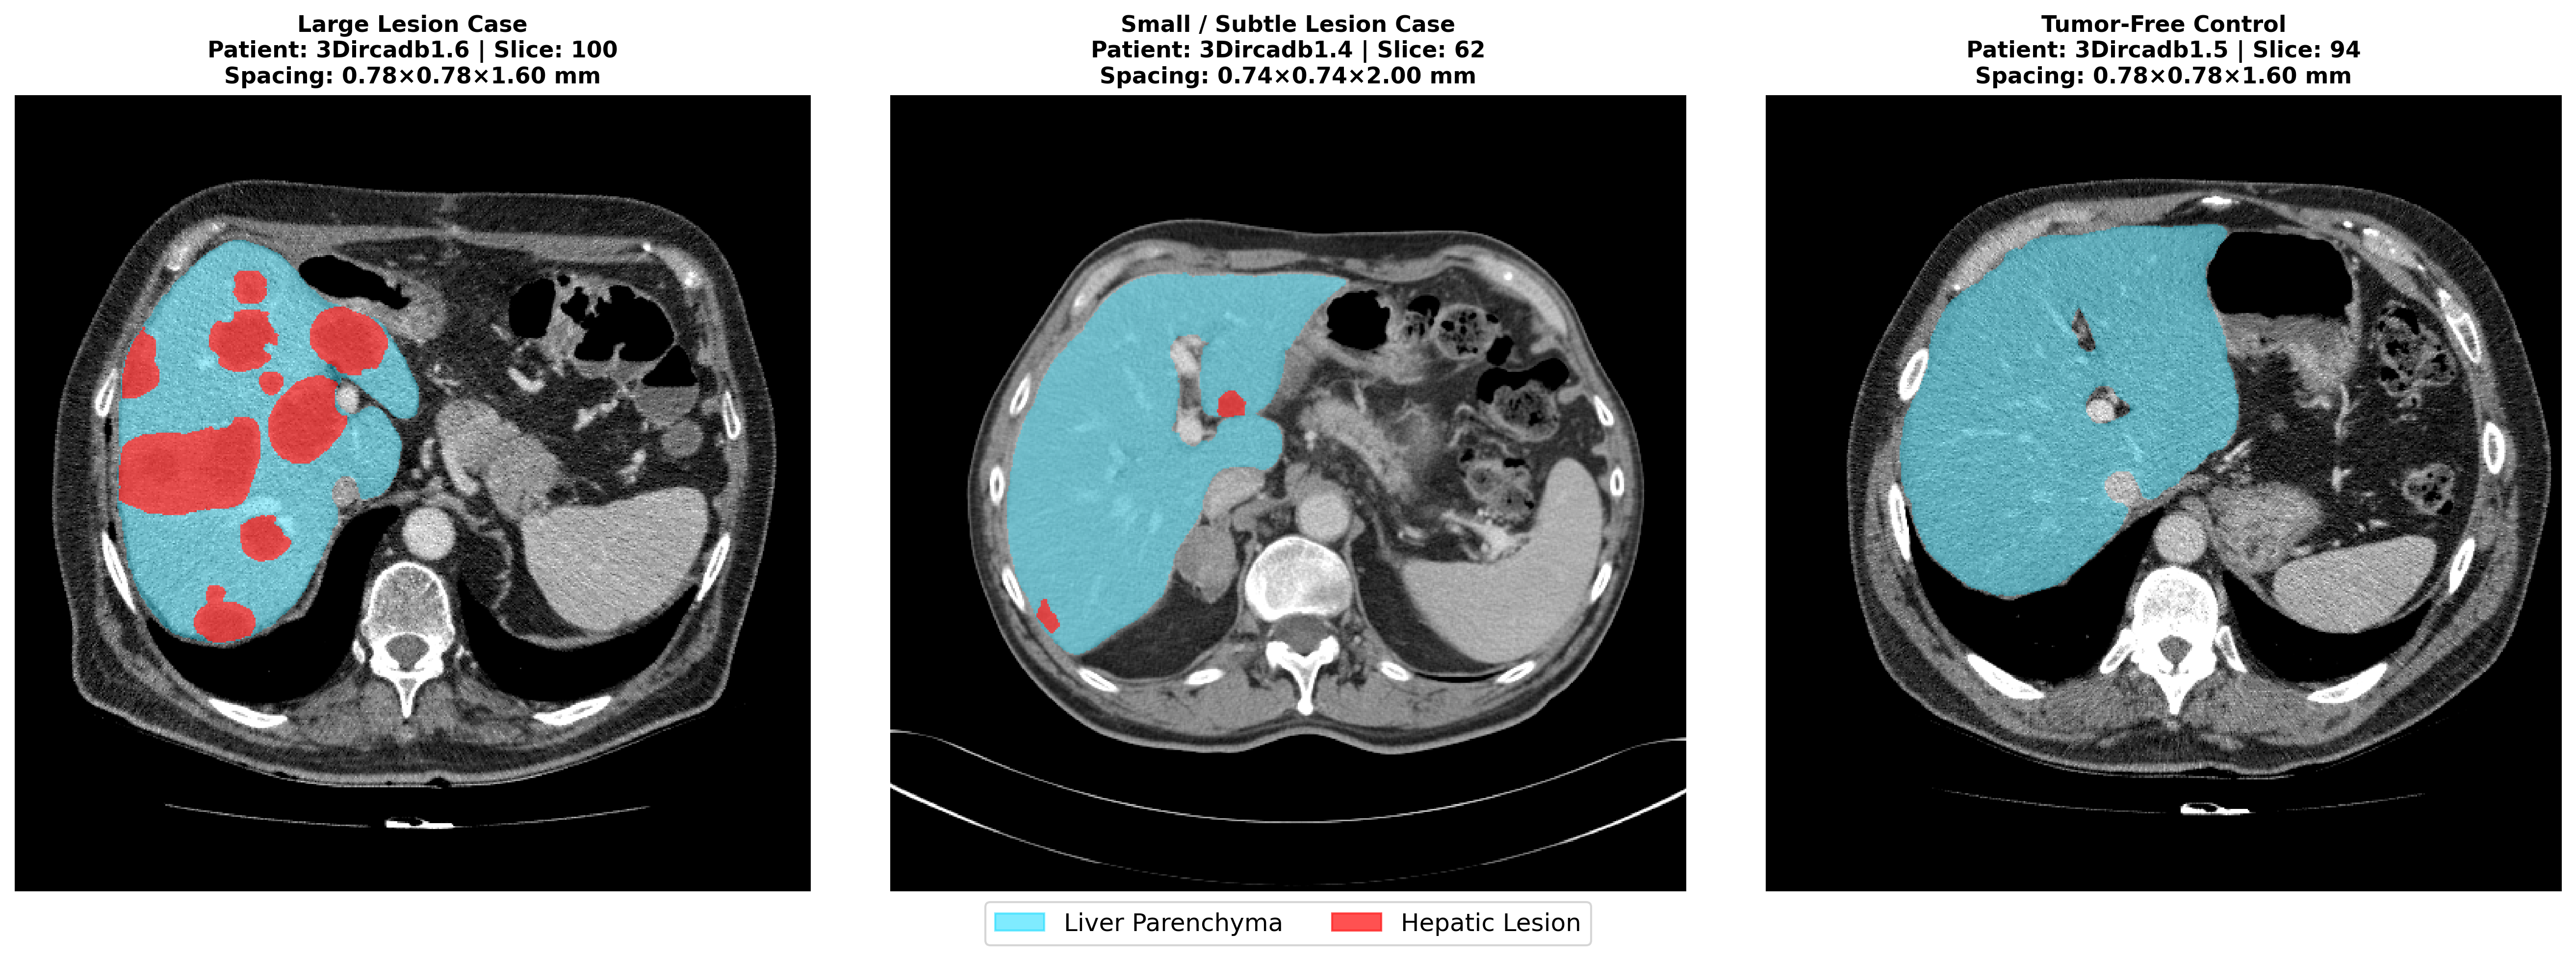

In [16]:
def window_ct(
    ct_slice: np.ndarray, window_level: float = 40, window_width: float = 400
) -> np.ndarray:
    """Applies clinical soft-tissue windowing (default: WL=40, WW=400 HU)

    and scales output to [0, 1].
    """
    lower = window_level - (window_width / 2.0)
    upper = window_level + (window_width / 2.0)
    clipped = np.clip(ct_slice, lower, upper)
    return (clipped - lower) / (upper - lower)


# Identify index of 3 representative patient archetypes
# 1. Tumor-free
tumor_free_id = df_patients.loc[~df_patients["Has_Tumor"], "Patient_ID"].iloc[0]
idx_tf = [
    i for i, p in enumerate(parser.patient_dirs) if p.name == tumor_free_id
][0]

# 2. Large tumor (Max total tumor volume)
large_tumor_id = df_patients.loc[
    df_patients["Tumor_Vol (cm3)"].idxmax(), "Patient_ID"
]
idx_lg = [
    i for i, p in enumerate(parser.patient_dirs) if p.name == large_tumor_id
][0]

# 3. Small tumor
small_tumor_id = df_lesions.sort_values("Volume_cm3").iloc[2]["Patient_ID"]
idx_sm = [
    i for i, p in enumerate(parser.patient_dirs) if p.name == small_tumor_id
][0]

case_indices = [
    (idx_lg, "Large Lesion Case"),
    (idx_sm, "Small / Subtle Lesion Case"),
    (idx_tf, "Tumor-Free Control"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=300)

for ax_idx, (p_idx, label_desc) in enumerate(case_indices):
    pat = parser.load_patient(p_idx)

    # Find the axial slice containing the largest tumor cross-section (or mid-liver for control)
    if pat.has_tumor:
        slice_sums = np.sum(pat.tumor_mask, axis=(1, 2))
        best_slice = int(np.argmax(slice_sums))
    else:
        slice_sums = np.sum(pat.liver_mask, axis=(1, 2))
        best_slice = int(np.argmax(slice_sums))

    ct_slice = pat.image[best_slice, :, :]
    liver_s = pat.liver_mask[best_slice, :, :]
    tumor_s = pat.tumor_mask[best_slice, :, :]

    # Window CT image
    ct_norm = window_ct(ct_slice, window_level=40, window_width=400)

    # Render base CT
    axes[ax_idx].imshow(ct_norm, cmap="gray", origin="upper")

    # Render Liver overlay
    liver_overlay = np.zeros((*liver_s.shape, 4))
    liver_overlay[liver_s & ~tumor_s] = [0.0, 0.85, 1.0, 0.35]
    axes[ax_idx].imshow(liver_overlay, origin="upper")

    # Render Tumor overlay
    tumor_overlay = np.zeros((*tumor_s.shape, 4))
    tumor_overlay[tumor_s] = [1.0, 0.15, 0.15, 0.70]
    axes[ax_idx].imshow(tumor_overlay, origin="upper")

    dz, dy, dx = pat.spacing
    axes[ax_idx].set_title(
        f"{label_desc}\nPatient: {pat.patient_id} | Slice: {best_slice}\n"
        f"Spacing: {dx:.2f}×{dy:.2f}×{dz:.2f} mm",
        fontsize=11,
        fontweight="bold",
    )
    axes[ax_idx].axis("off")

# Add unified clinical legend
liver_patch = mpatches.Patch(
    color=[0.0, 0.85, 1.0, 0.5], label="Liver Parenchyma"
)
tumor_patch = mpatches.Patch(color=[1.0, 0.15, 0.15, 0.8], label="Hepatic Lesion")
fig.legend(
    handles=[liver_patch, tumor_patch],
    loc="lower center",
    ncol=2,
    fontsize=12,
    frameon=True,
    bbox_to_anchor=(0.5, -0.05),
)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "fig1_axial_overlays.png", dpi=300, bbox_inches="tight"
)
plt.show()

______

# Tumor Volume Distribution

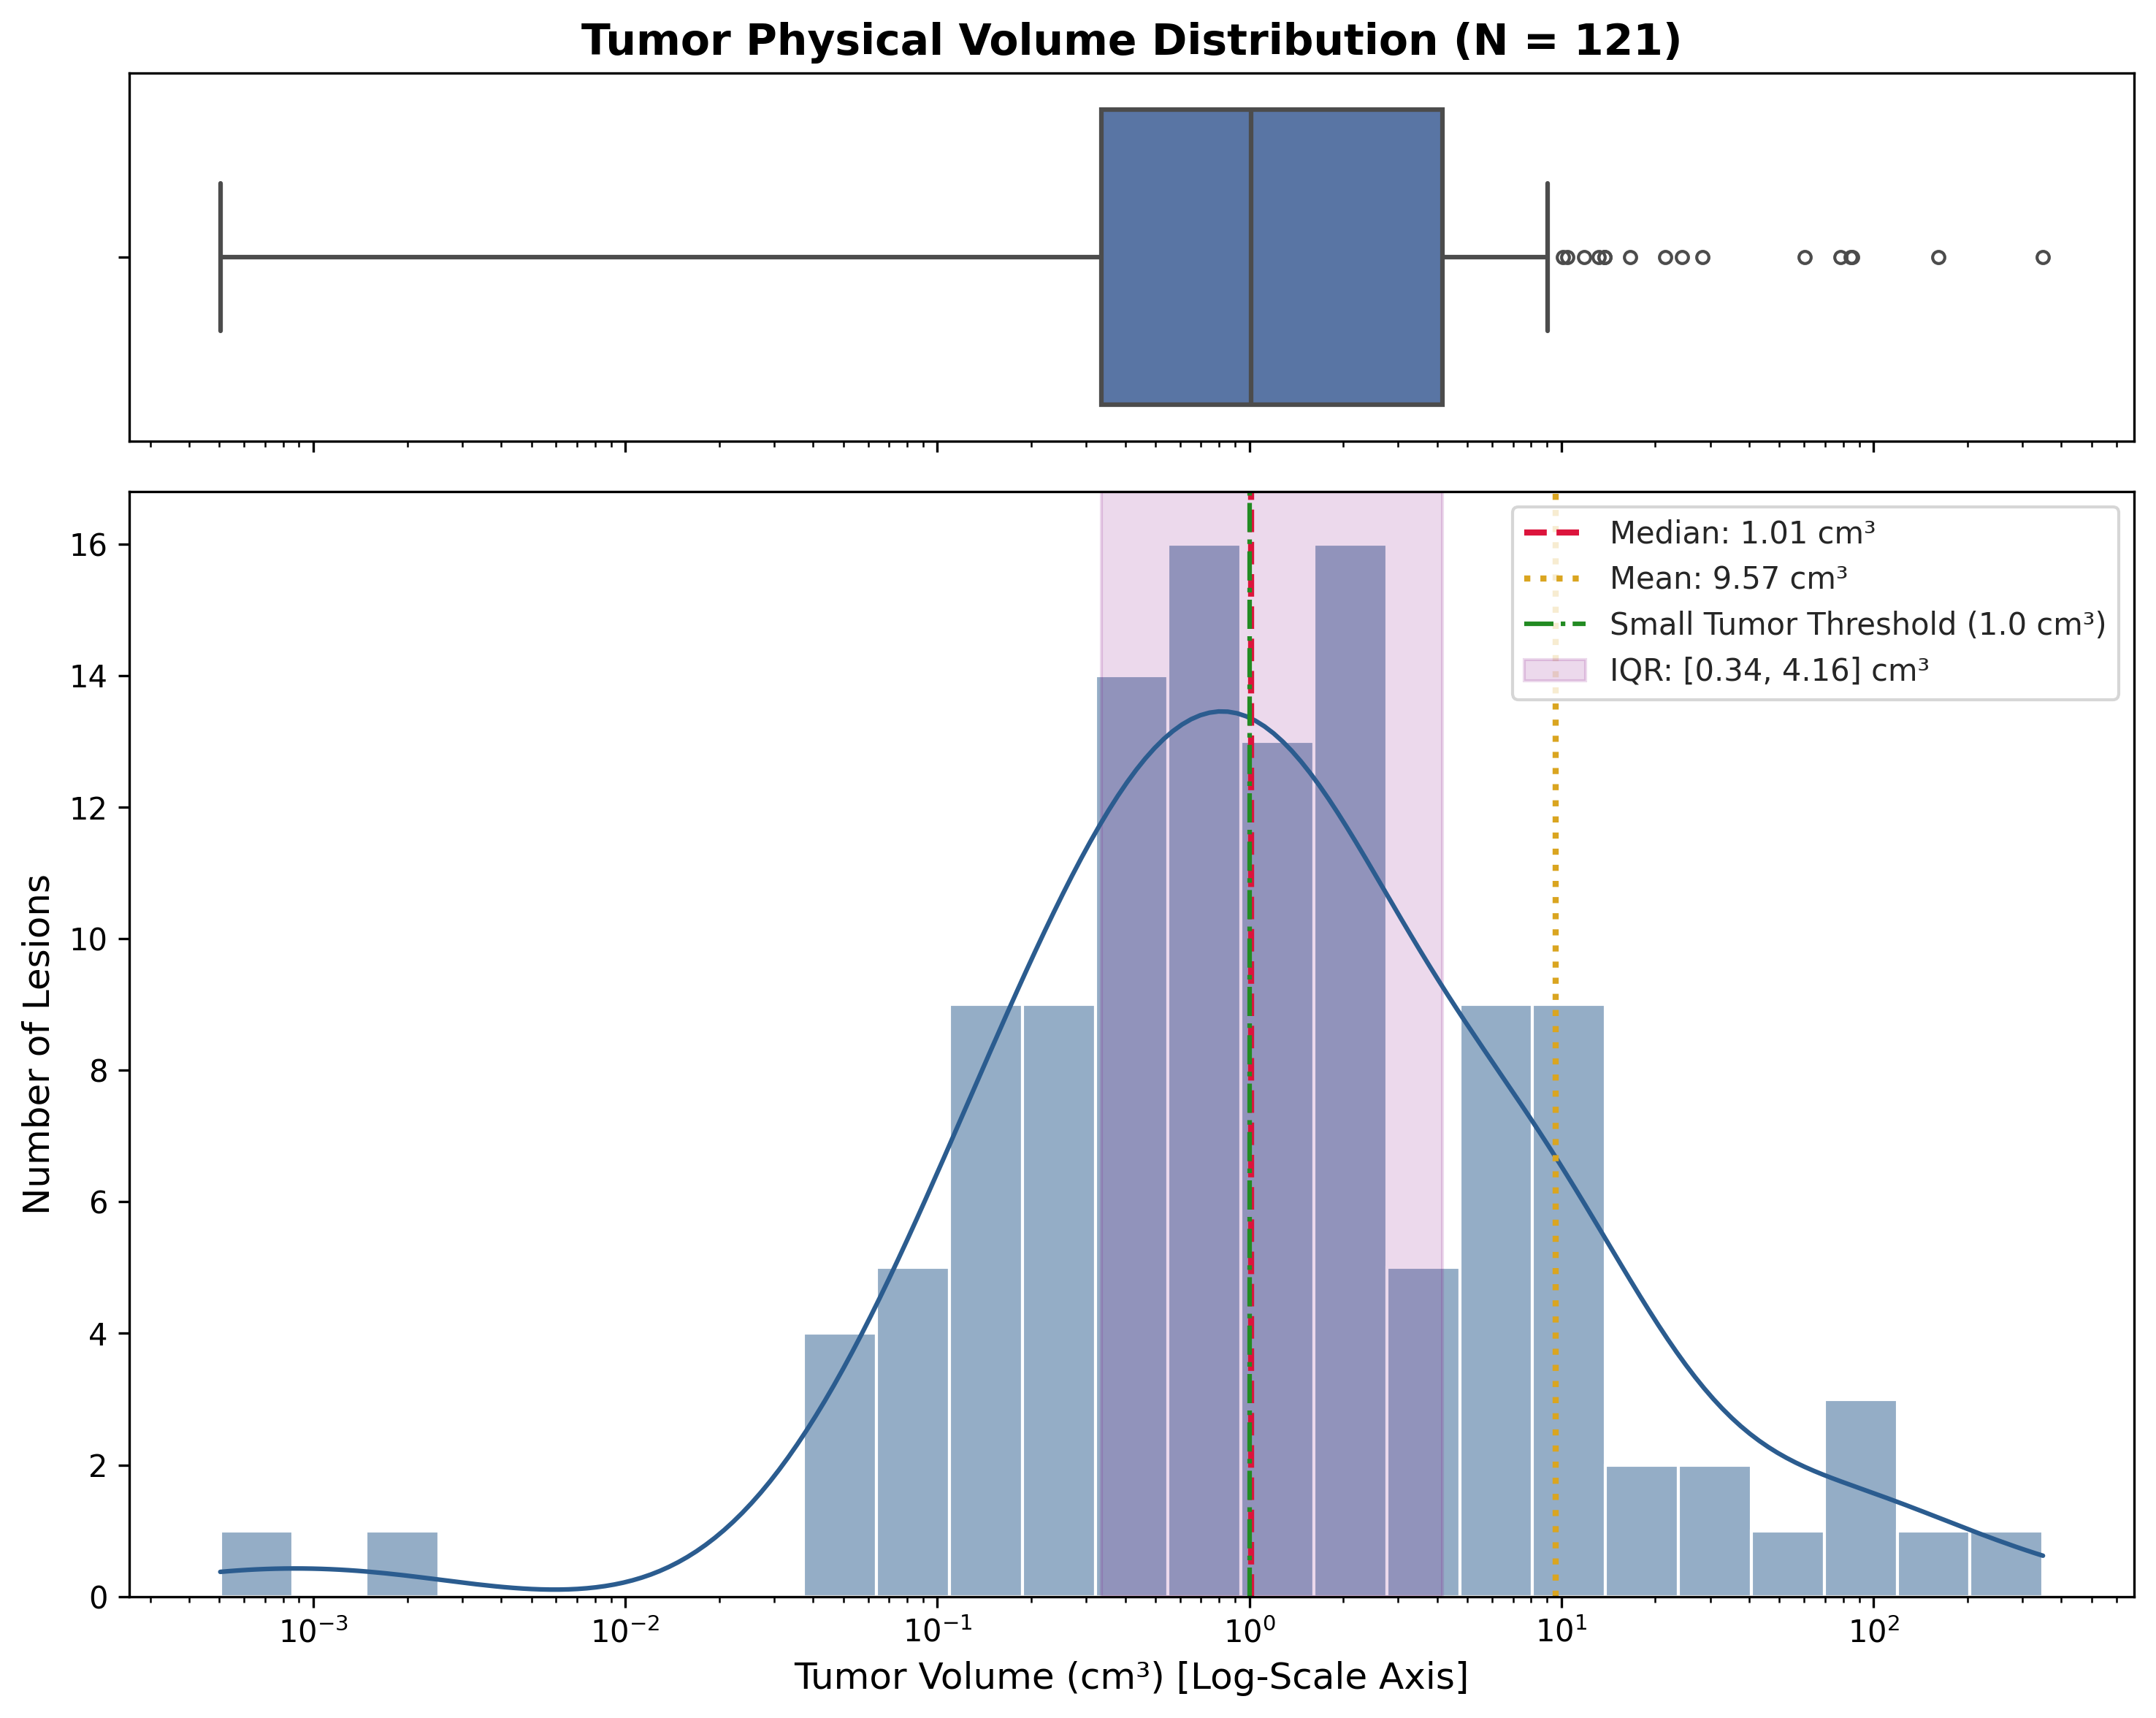

In [17]:
fig, (ax_box, ax_hist) = plt.subplots(
    2,
    1,
    figsize=(10, 8),
    gridspec_kw={"height_ratios": [0.25, 0.75]},
    sharex=True,
    dpi=300,
)

sns.set_theme(style="whitegrid")

# Top: Boxplot with outlier points
sns.boxplot(
    x=df_lesions["Volume_cm3"],
    ax=ax_box,
    color="#4C72B0",
    fliersize=4,
    linewidth=1.5,
)
ax_box.set(xscale="log", xlabel="")
ax_box.set_title(
    "Tumor Physical Volume Distribution (N = " + str(len(df_lesions)) + ")",
    fontsize=14,
    fontweight="bold",
)

# Bottom: Histogram + KDE on Log Scale
sns.histplot(
    data=df_lesions,
    x="Volume_cm3",
    bins=25,
    kde=True,
    color="#2b5c8f",
    ax=ax_hist,
    log_scale=True,
)

# Annotate landmark lines
median_vol = df_lesions["Volume_cm3"].median()
mean_vol = df_lesions["Volume_cm3"].mean()
q25 = df_lesions["Volume_cm3"].quantile(0.25)
q75 = df_lesions["Volume_cm3"].quantile(0.75)

ax_hist.axvline(
    median_vol,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_vol:.2f} cm³",
)
ax_hist.axvline(
    mean_vol,
    color="goldenrod",
    linestyle=":",
    linewidth=2,
    label=f"Mean: {mean_vol:.2f} cm³",
)
ax_hist.axvline(
    1.0,
    color="forestgreen",
    linestyle="-.",
    linewidth=1.5,
    label="Small Tumor Threshold (1.0 cm³)",
)

# Add IQR shading
ax_hist.axvspan(
    q25,
    q75,
    alpha=0.15,
    color="purple",
    label=f"IQR: [{q25:.2f}, {q75:.2f}] cm³",
)

ax_hist.set_xlabel("Tumor Volume (cm³) [Log-Scale Axis]", fontsize=12)
ax_hist.set_ylabel("Number of Lesions", fontsize=12)
ax_hist.legend(loc="upper right", frameon=True, fontsize=10)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "fig2_tumor_volume_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

______

# Voxel Class Distribution

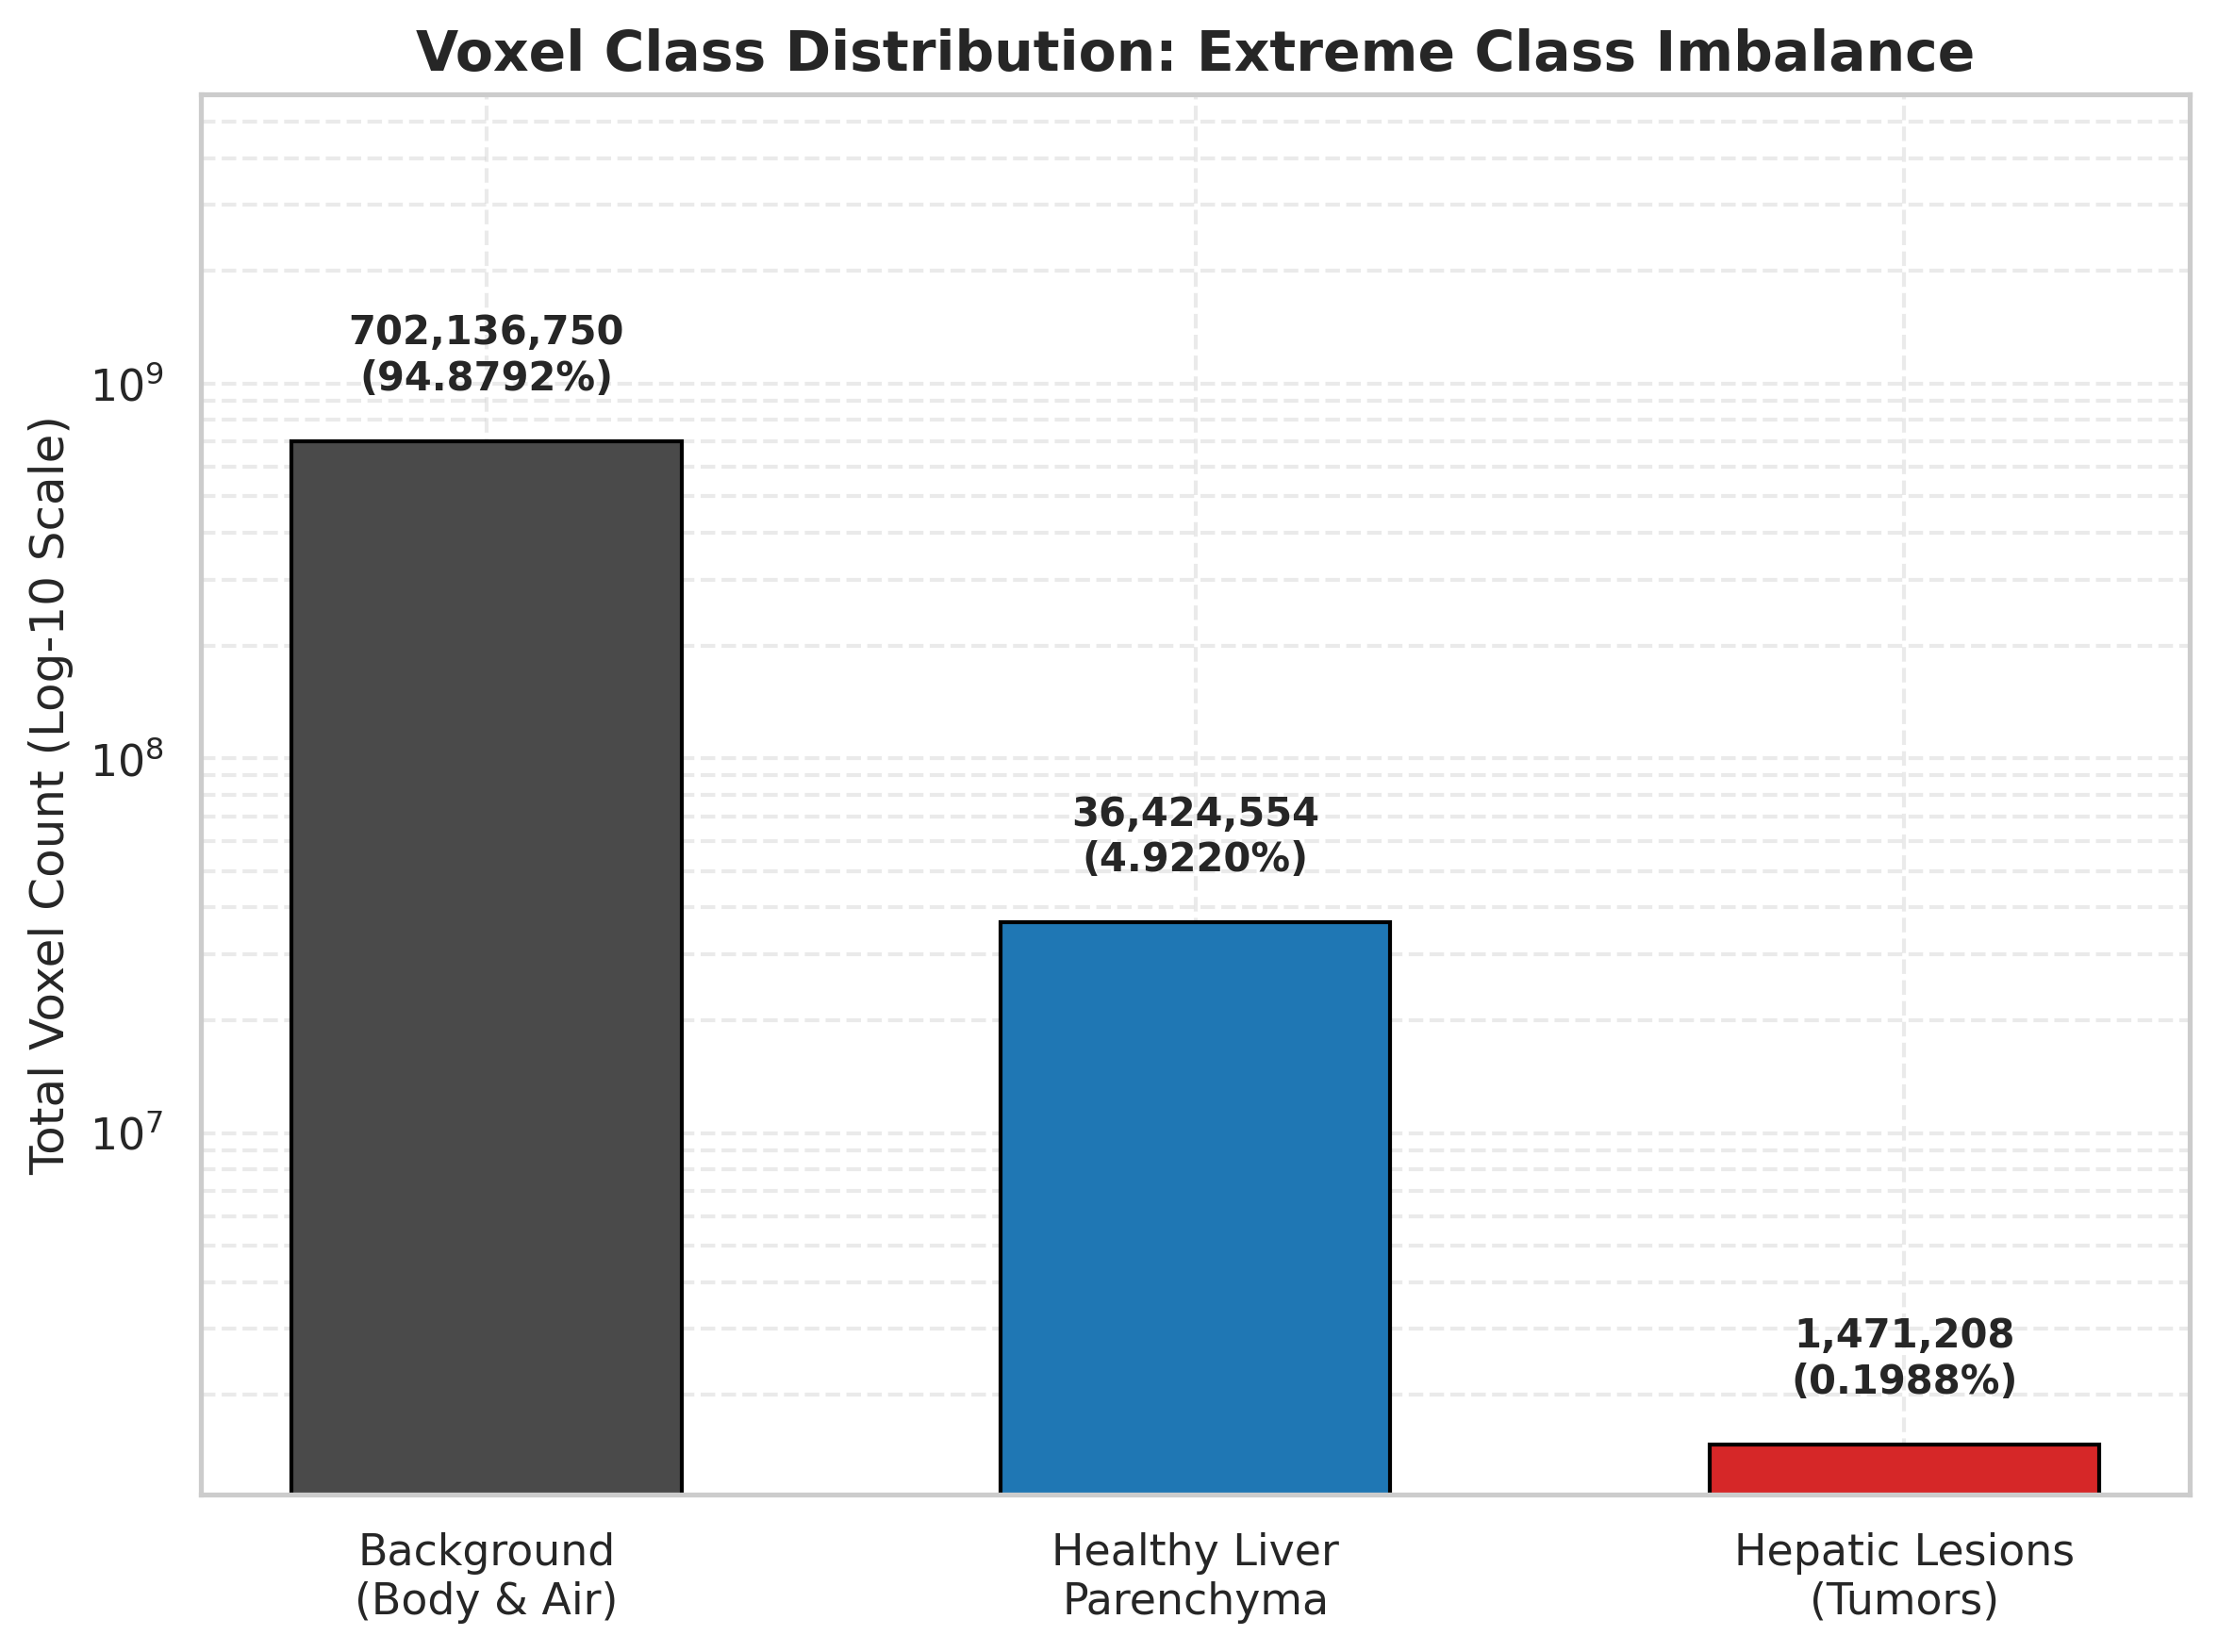

In [18]:
fig, ax1 = plt.subplots(figsize=(8, 6), dpi=300)

classes = [
    "Background\n(Body & Air)",
    "Healthy Liver\nParenchyma",
    "Hepatic Lesions\n(Tumors)",
]
counts = [total_voxels_bg, total_voxels_liver, total_voxels_tumor]
percentages = [pct_bg, pct_liver, pct_tumor]
colors = ["#4A4A4A", "#1F77B4", "#D62728"]

bars = ax1.bar(classes, counts, color=colors, width=0.55, edgecolor="black")

ax1.set_yscale("log")
ax1.set_ylabel("Total Voxel Count (Log-10 Scale)", fontsize=12)
ax1.set_title("Voxel Class Distribution: Extreme Class Imbalance", fontsize=14, fontweight="bold")
ax1.grid(True, which="both", ls="--", alpha=0.4)

# Annotate bars with both absolute counts and percentages
for bar, count, pct in zip(bars, counts, percentages):
    yval = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2.0,
        yval * 1.3,
        f"{count:,}\n({pct:.4f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax1.set_ylim(top=total_all_vox * 8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig3_class_balance.png", dpi=300, bbox_inches="tight")
plt.show()

_____

# Slice-wise Lesion Continuity and Z-Axis Sparsity

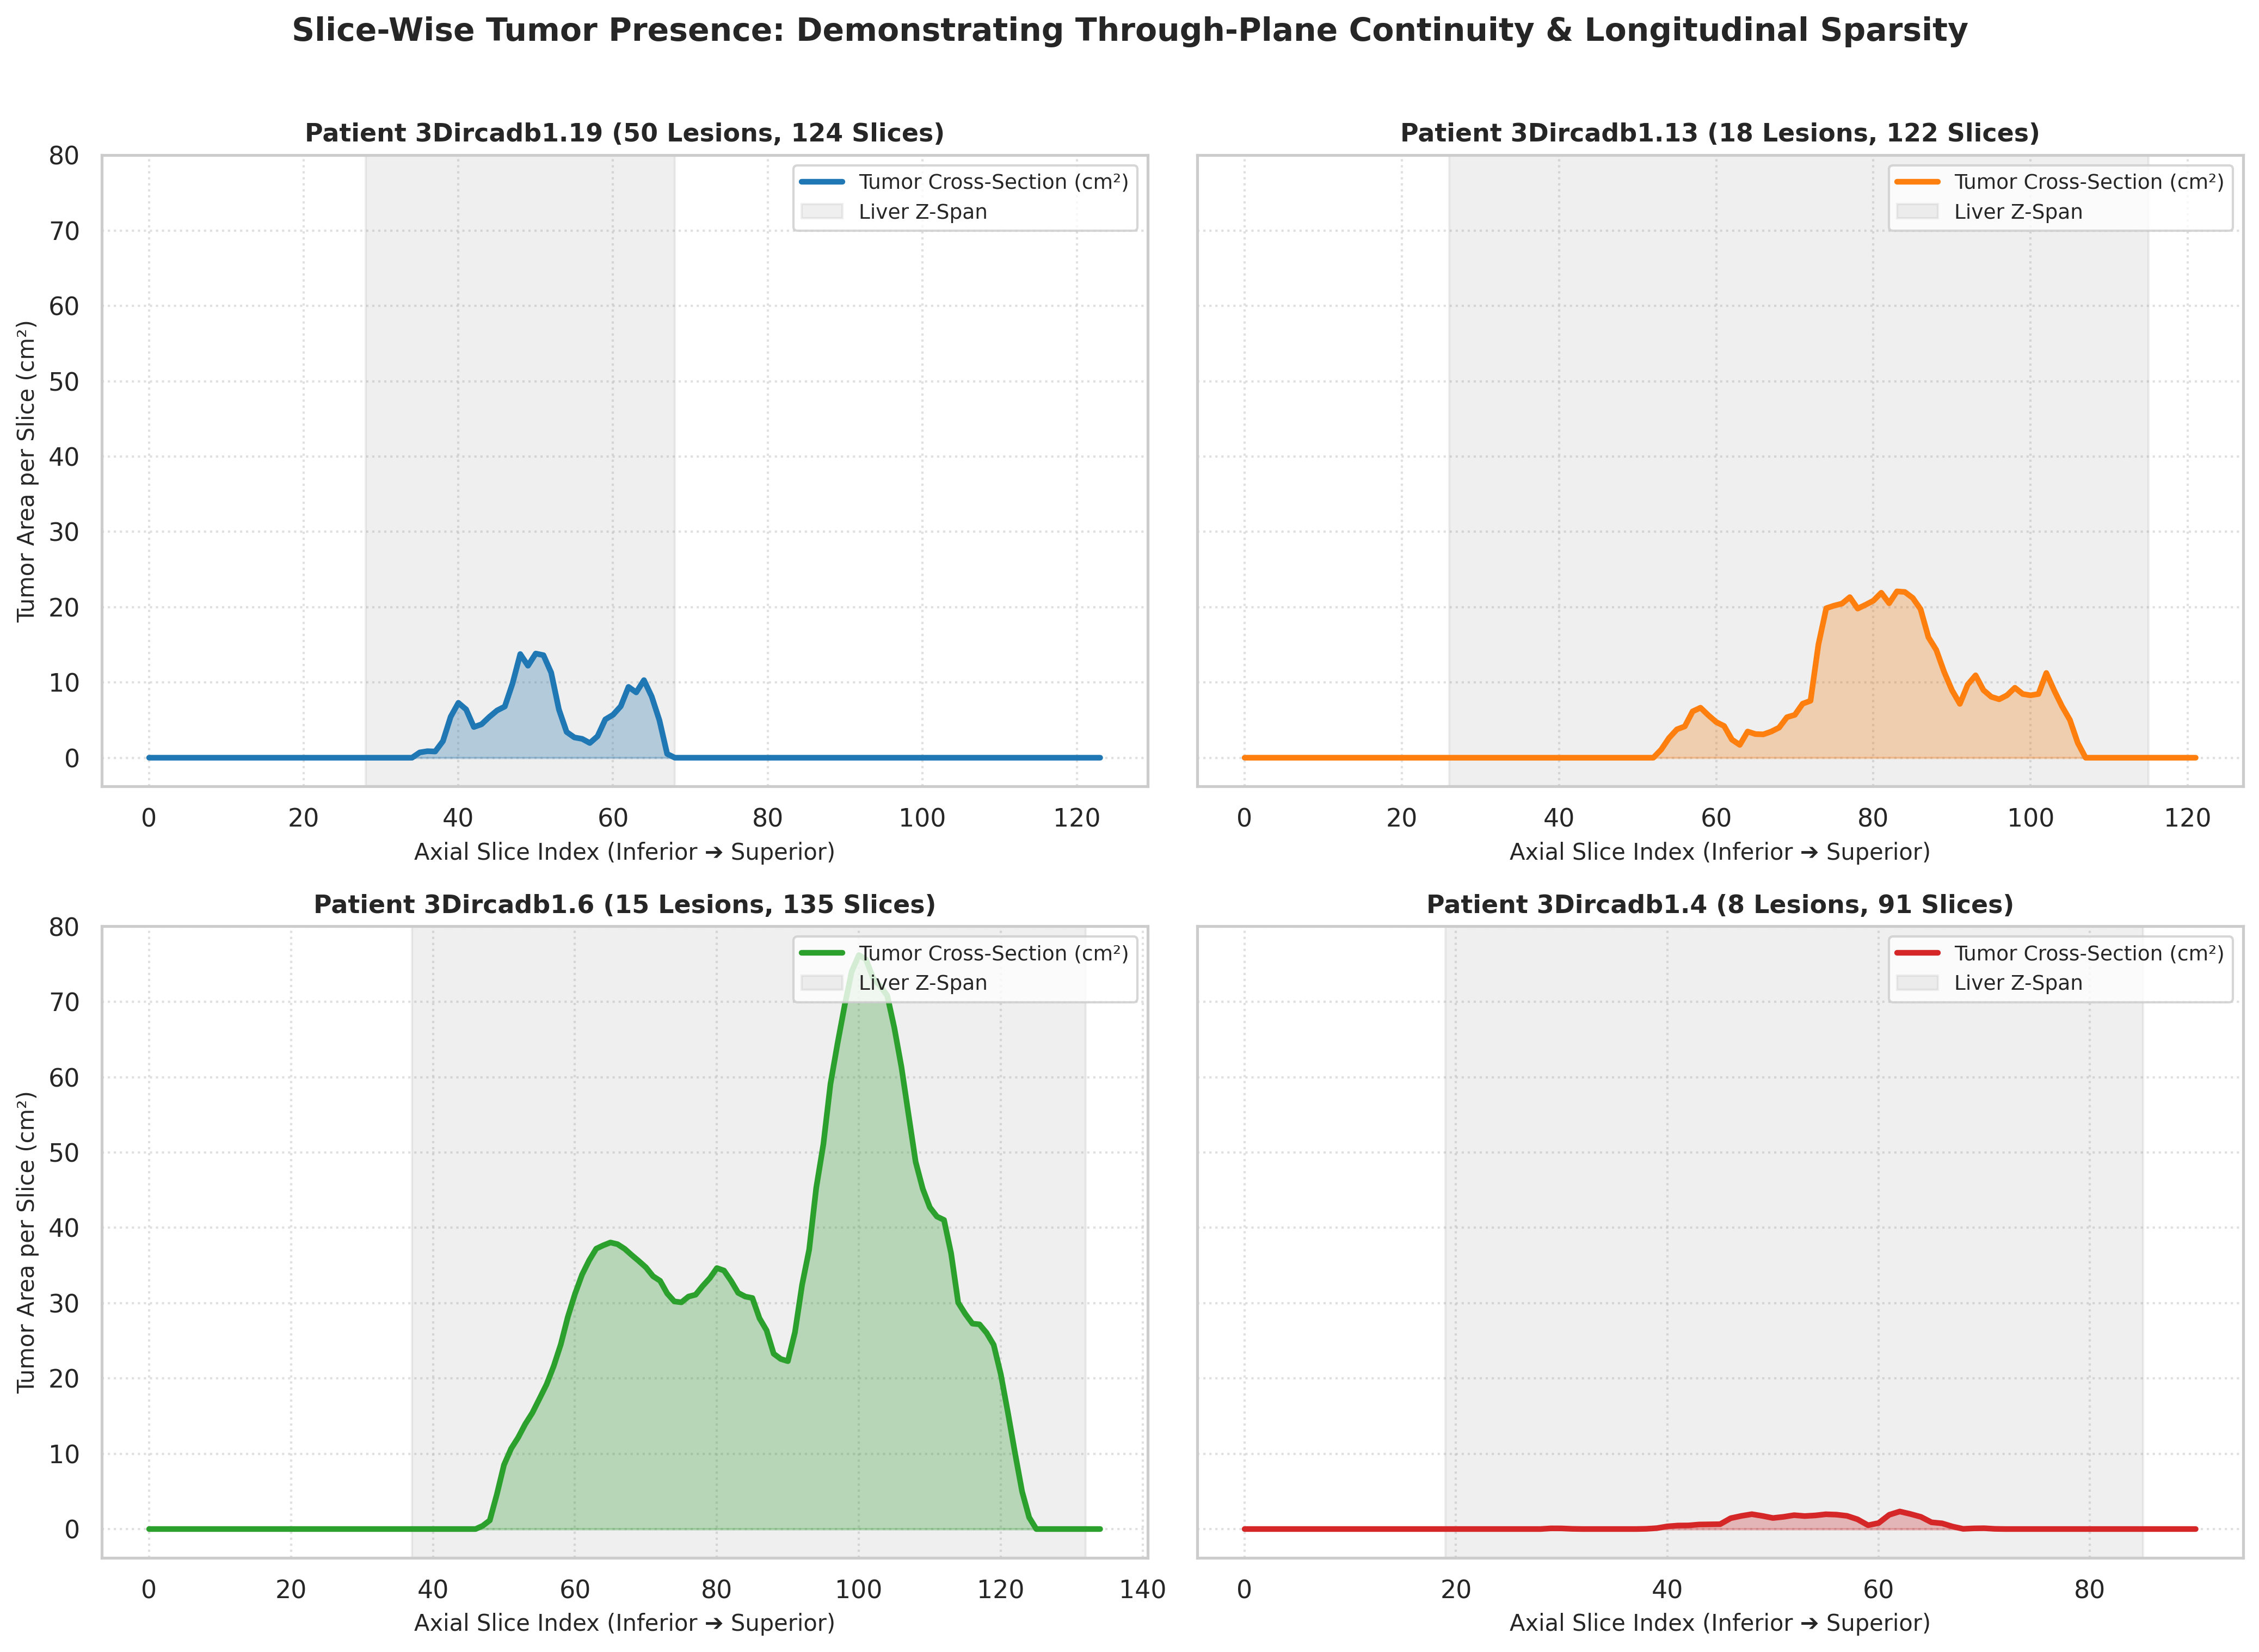

In [19]:
# Select 4 representative patients exhibiting multiple lesions
selected_cases = [
    pid
    for pid in df_patients.sort_values(
        "Tumor_Count", ascending=False
    )["Patient_ID"]
    if df_patients.loc[df_patients["Patient_ID"] == pid, "Tumor_Count"].values[0]
    >= 2
][:4]

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True, dpi=300)
axes = axes.flatten()

palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for i, pid in enumerate(selected_cases):
    pat_idx = [
        idx
        for idx, p in enumerate(parser.patient_dirs)
        if p.name == pid
    ][0]
    pat = parser.load_patient(pat_idx)

    # Compute tumor voxel count per slice along z-axis
    tumor_vox_per_slice = np.sum(pat.tumor_mask, axis=(1, 2))
    liver_vox_per_slice = np.sum(pat.liver_mask, axis=(1, 2))
    slice_indices = np.arange(pat.num_slices)

    # Convert to physical area in cm² (dy * dx)
    area_factor = (pat.spacing[1] * pat.spacing[2]) / 100.0  # mm² to cm²
    tumor_area_cm2 = tumor_vox_per_slice * area_factor

    axes[i].plot(
        slice_indices,
        tumor_area_cm2,
        color=palette[i],
        linewidth=2.5,
        label=f"Tumor Cross-Section (cm²)",
    )
    axes[i].fill_between(
        slice_indices, 0, tumor_area_cm2, color=palette[i], alpha=0.3
    )

    # Overlay liver presence boundary as background span
    liver_slices = np.where(liver_vox_per_slice > 0)[0]
    if len(liver_slices) > 0:
        axes[i].axvspan(
            liver_slices[0],
            liver_slices[-1],
            color="gray",
            alpha=0.12,
            label="Liver Z-Span",
        )

    axes[i].set_title(
        f"Patient {pid} ({pat.num_tumors} Lesions, {pat.num_slices} Slices)",
        fontweight="bold",
        fontsize=11,
    )
    axes[i].set_xlabel("Axial Slice Index (Inferior ➔ Superior)", fontsize=10)
    axes[i].grid(True, linestyle=":", alpha=0.6)
    if i % 2 == 0:
        axes[i].set_ylabel("Tumor Area per Slice (cm²)", fontsize=10)
    axes[i].legend(loc="upper right", fontsize=9)

plt.suptitle(
    "Slice-Wise Tumor Presence: Demonstrating Through-Plane Continuity & Longitudinal Sparsity",
    fontsize=14,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "fig4_slicewise_presence.png", dpi=300, bbox_inches="tight"
)
plt.show()

Liver tissue and tumor are present only in a limited number of slices, which can be used for optimization purposes.

# Key takeaways

1. Extreme class imbalance with strongly dominating background

2. Most patients with liver tumor have multiple tumors

3. Tumor volume has asymetrical distribution skewed to the right

4. Tumors are rather smaller (IQR $\in [0.34, 4.16]$ $cm^3$)

5. There are a significant number of slices that contain neither healthy liver parenchyma nor tumor  